# Personalization of the UPMaBoSS cell fate model : TCGA colon adenocarcinomas (GDC)
The PROFILE approach applied to the UPMaBoSS formalism : one personalized cell fate model per primary colon
adenocarcinoma of TCGA-COAD (GDC harmonized data, hg38, cBioPortal `coad_tcga_gdc`, `data/coad_tcga_gdc/`), each
simulated as a population of cells with UPMaBoSS. Adapted from the Grieco MAPK version
(`pyPROFILE/vignettes/Grieco_model/03_model_personalization_carcinoma_TCGA_COAD_GDC.ipynb`), with these changes :
1. Model : the cell fate model of `data/model/CellFate/` (Calzone et al. 2010, modified for UPMaBoSS by Stoll et al.
   2022, see `CellFateModel_uppmaboss.ipynb`). At each step of 1 h (48 steps), the `.upp` file removes the cells in
   `Death`, duplicates the cells in `Division`, and sets the paracrine TNF production `$TNF_induc` from the fraction of
   living cells with active NFkB.
2. Initial state : the one of the core `.cfg` (pulse of TNF at t = 0), kept in every model (`skip_initial_states=True`).
3. The CellFate model writes its rates as constants (`1.0`, `$TransRate`) : a `$u_<node>` / `$d_<node>` factor (= 1) is
   added to the rates of the personalized nodes, and pyPROFILE scales these factors with the expression.
4. Only the gene-product nodes are personalized : the inputs (`TNF`, `FASL`), the complexes, the modified forms of RIP1
   and the protein forms of the IAPs follow their components through the logic of the model.
5. Expression : GDC STAR TPM (`data_mrna_seq_tpm.txt`), Entrez IDs mapped to HGNC symbols ; the TPM of the genes of a
   node are summed ; only the nodes above the genome-wide LOESS trend (SD vs mean) personalize the rates. No
   transcription factor activity.
6. Readouts : the population ratio (size of the population relative to t = 0) and the node probabilities in the living
   cells at each step, saved in `analysis/CellFate_model/results/`, and compared with the AJCC pathologic stage of the
   tumour (`data_clinical_patient.txt`) as the severity of the disease.
   Before UPMaBoSS, the personalized models are simulated once with plain MaBoSS (single cells, no population
   update), as a check of what the personalization does.

In [ ]:
import os
import re
import sys
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import maboss
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.nonparametric.smoothers_lowess import lowess
from tqdm.auto import tqdm

# Work from the root of the repository (UppMaBoSS_PROFILE)
if Path.cwd().name == 'CellFate_model':
    os.chdir('../../')

# pyPROFILE is not installed in the environment : it is imported from its repository, next to this one.
# Its data/Common folder holds the HUGO <-> Entrez table and the mutation databases.
PYPROFILE_DIR = Path('../pyPROFILE').resolve()
sys.path.insert(0, str(PYPROFILE_DIR))
import pyPROFILE as profile
COMMON_DIR = PYPROFILE_DIR / 'data' / 'Common'

# Path to the model and data, and where to save the results and figures
MODEL_PREFIX = 'data/model/CellFate/CellFateModel_uppmaboss'
DATA_DIR = 'data/coad_tcga_gdc'
RESULTS_DIR = 'analysis/CellFate_model/results'
FIG_DIR = 'analysis/CellFate_model/figures/personalization_TCGA_COAD_GDC'
PROJECT_NAME = 'CellFate_TCGA_COAD_GDC'
for folder in (RESULTS_DIR, FIG_DIR):
    os.makedirs(folder, exist_ok=True)

# 1. Load the model and the data
## Model
The core model (`.bnd`, `.cfg`) and its population update file (`.upp`). `max_time` = 1 in the `.cfg` is the duration
of one UPMaBoSS step (1 h) and is kept. The initial state is the one of the `.cfg` : TNF ON (pulse at t = 0) ; the nodes
without an initial state in the `.cfg` start ON with probability 0.5 (listed below).

In [2]:
model = maboss.load(MODEL_PREFIX + '.bnd', MODEL_PREFIX + '.cfg')
upp_file = MODEL_PREFIX + '.upp'
print(open(upp_file).read())

upp = maboss.UpdatePopulation(model, upp_file)
n_steps, step_duration = upp.step_number, upp.time_step
print(f'{n_steps} steps of {step_duration:g} h')

# Probability of each node to be ON at t = 0 (nodes always OFF not shown)
istate = pd.Series({node: float(state[1]) for node, state in model.network.get_istate().items()}, name='P(ON) at t = 0')
istate[istate > 0].to_frame()

death = Death;
division = Division ;
$TNF_induc u= $ProdTNF_NFkB*p[(NFkB,Death) = (1,0)];
steps = 48;
MaBoSS = MaBoSS

48 steps of 1 h


,P(ON) at t = 0
TNF,1.0
FADD,0.5
mROS,0.5
ATP,0.5
mcIAP,0.5
cIAP,0.5
mXIAP,0.5
Division,0.5
Death,0.5


## Node -> genes dictionary
`CellFateModel_dictionary.csv` : multi-gene entries (e.g. `['NFKB1', 'RELA']`) are split into lists. The nodes without
genes (`mROS`, `ROS`, `ATP`, `MPT`, `MOMP` and the phenotypes) are never personalized. Of the nodes with genes, only the
gene products personalize the model (mutations and rates) ; excluded :
- `TNF`, `FASL` : inputs, the treatment (pulse of TNF, then paracrine TNF set by the `.upp`) ;
- `DISC_TNF`, `DISC_FAS`, `apoptosome` : complexes, formed by the logic from their personalized components
  (`TRADD`, `APAF1`, `CASP9` are only in the complexes and are not used) ;
- `RIP1ub`, `RIP1K` : ubiquitinated / kinase forms of `RIP1`, which carries `RIPK1` ;
- `cIAP`, `XIAP` : proteins of the transcripts `mcIAP`, `mXIAP`, which carry the RNA-seq of `BIRC2`/`BIRC3` and `XIAP`.

`FADD` has null rates in the core model (constant at its initial state) : scaling its rates has no effect, only its
mutations act.

In [3]:
dictionary = pd.read_csv('data/model/CellFate/CellFateModel_dictionary.csv')
node_genes = {node: re.findall(r"[A-Z0-9]+", str(genes)) for node, genes in zip(dictionary['Node'], dictionary['UniProt'])}
node_genes = {node: genes for node, genes in node_genes.items() if genes}

# Remove nodes that are not mapped to genes - including inputs and complexes
excluded_nodes = ['TNF', 'FASL', 'DISC_TNF', 'DISC_FAS', 'apoptosome', 'RIP1ub', 'RIP1K', 'cIAP', 'XIAP']
node_genes = {node: genes for node, genes in node_genes.items() if node not in excluded_nodes}
assert set(node_genes) <= set(model.network.names), set(node_genes) - set(model.network.names)
model_genes = sorted({gene for genes in node_genes.values() for gene in genes})
print(len(node_genes), 'nodes mapped to', len(model_genes), 'genes')
pd.Series(node_genes).str.join(', ').rename('genes').to_frame()

12 nodes mapped to 15 genes


,genes
TNFR,TNFRSF1A
FADD,FADD
RIP1,RIPK1
IKK,"CHUK, IKBKB, IKBKG"
NFkB,"NFKB1, RELA"
CASP8,CASP8
BAX,BAX
BCL2,BCL2
SMAC,DIABLO
Cyt_c,CYCS


## Gene expression and clinical data
RNA-seq (STAR TPM, `data_mrna_seq_tpm.txt`) of the primary tumours, with the sample (`data_clinical_sample.txt`) and
patient (`data_clinical_patient.txt`) annotations. Entrez IDs are mapped to HGNC symbols ; unmapped IDs are dropped, and
rows sharing an Entrez ID or a symbol (a few genes quantified as several Ensembl genes) are summed.
Pathologic stage : the AJCC sub-stages (e.g. `Stage IIIB`) are collapsed into the main stage I to IV. Tumours without a
recorded stage are kept in the models but left out of the stage comparisons.

In [4]:
hugo = pd.read_csv(COMMON_DIR / 'HUGO_Entrez.txt', sep='\t').dropna(subset='Entrez Gene ID')
entrez_symbol = dict(zip(hugo['Entrez Gene ID'].astype(int), hugo['Approved Symbol']))

# Load RNA data
TCGA_RNA = pd.read_csv(f'{DATA_DIR}/data_mrna_seq_tpm.txt', sep='\t', index_col=0)
TCGA_RNA = TCGA_RNA.groupby(TCGA_RNA.index.map(entrez_symbol)).sum()   # unmapped IDs (NaN) are dropped
TCGA_RNA.index.name = None
TCGA_RNA = TCGA_RNA.T.astype(float)   # tumours x genes, TPM

# Load clinical data
TCGA_clin = pd.read_csv(f'{DATA_DIR}/data_clinical_sample.txt', sep='\t', comment='#').set_index('SAMPLE_ID')
TCGA_clin = TCGA_clin[TCGA_clin['SAMPLE_TYPE'] == 'Primary Tumor']
TCGA_clin = TCGA_clin.loc[TCGA_clin.index.intersection(TCGA_RNA.index)]
TCGA_patient = pd.read_csv(f'{DATA_DIR}/data_clinical_patient.txt', sep='\t', comment='#').set_index('PATIENT_ID')
TCGA_clin = TCGA_clin.join(TCGA_patient, on='PATIENT_ID')
TCGA_clin['STAGE'] = TCGA_clin['PATH_STAGE'].str.extract(r'Stage (IV|I{1,3})', expand=False).fillna('NA')

# Summarize the number of tumours per stage
TCGA_RNA = TCGA_RNA.loc[TCGA_clin.index]
samples = list(TCGA_clin.index)
print(len(samples), 'tumours')
pd.crosstab(TCGA_clin['PATH_STAGE'].fillna('NA'), TCGA_clin['STAGE'], margins=True)

458 tumours


STAGE,I,II,III,IV,NA,All
PATH_STAGE,,,,,,
NA,0,0,0,0,13,13
Stage I,74,0,0,0,0,74
Stage IA,1,0,0,0,0,1
Stage II,0,30,0,0,0,30
Stage IIA,0,136,0,0,0,136
Stage IIB,0,10,0,0,0,10
Stage IIC,0,1,0,0,0,1
Stage III,0,0,20,0,0,20
Stage IIIA,0,0,8,0,0,8


## Mutations
`data_mutations.txt` (MAF annotated with Genome Nexus, 402 MB, two `#` header lines), read by chunks : coding variants of
the model genes in the selected tumours, each listed once, renamed to the columns `profile.mutation_assignment` expects
(`HGVSp_Short` is the protein change, e.g. `p.V600E`).

In [5]:
columns = ['Tumor_Sample_Barcode', 'Hugo_Symbol', 'HGVSp_Short', 'Variant_Classification']
coding = ['Missense_Mutation', 'Nonsense_Mutation', 'Frame_Shift_Del', 'Frame_Shift_Ins', 'In_Frame_Del', 'In_Frame_Ins',
          'Splice_Site', 'Nonstop_Mutation', 'Translation_Start_Site']
chunks = pd.read_csv(f'{DATA_DIR}/data_mutations.txt', sep='\t', skiprows=2, usecols=columns, chunksize=1_000_000, low_memory=False)
TCGA_mut = pd.concat(chunk[chunk['Hugo_Symbol'].isin(model_genes) & chunk['Tumor_Sample_Barcode'].isin(samples)
                           & chunk['Variant_Classification'].isin(coding)] for chunk in chunks)
TCGA_mut = TCGA_mut.rename(columns={'Tumor_Sample_Barcode': 'model_name', 'Hugo_Symbol': 'gene_symbol',
                                    'HGVSp_Short': 'protein_mutation', 'Variant_Classification': 'effect'})
TCGA_mut = TCGA_mut.dropna(subset='protein_mutation').drop_duplicates(['model_name', 'gene_symbol', 'protein_mutation']).reset_index(drop=True)
print('Coding variants :', len(TCGA_mut), 'in', TCGA_mut['model_name'].nunique(), 'tumours')

Coding variants : 87 in 63 tumours


# 2. Gene expression -> transition rates
## Node expression
TPM summed over the genes of each node, then log2(x + 1).

In [6]:
print('Model genes missing from the expression data :', [g for g in model_genes if g not in TCGA_RNA.columns])
node_rna = pd.DataFrame({node: TCGA_RNA.reindex(columns=genes).sum(axis=1) for node, genes in node_genes.items()})
node_rna = np.log2(node_rna + 1)

Model genes missing from the expression data : []


## Node selection with the LOESS trend
LOESS trend of SD vs mean of every gene (log2(TPM + 1), same tumours). Nodes below the trend vary less than a typical
gene of similar expression. 

*These genes can be omitted from the personalization of the model.*

4 of 12 nodes above the trend


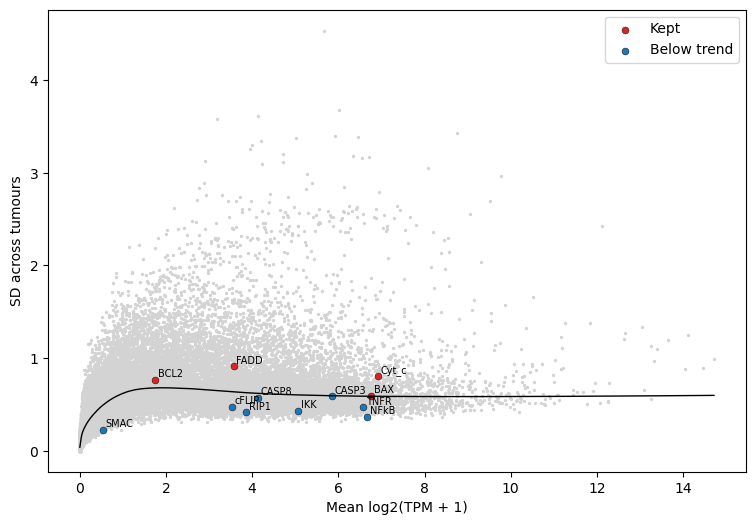

In [7]:
log_rna = np.log2(TCGA_RNA.dropna(axis=1) + 1)
stats = pd.DataFrame({'mean': log_rna.mean(), 'sd': log_rna.std()})
stats = stats[stats['mean'] > 0].sort_values('mean')
trend = lowess(stats['sd'], stats['mean'], frac=0.3, return_sorted=False)

node_stats = pd.DataFrame({'mean': node_rna.mean(), 'sd': node_rna.std()})
node_stats['residual'] = node_stats['sd'] - np.interp(node_stats['mean'], stats['mean'], trend)
node_stats['kept'] = node_stats['residual'] > 0
print(node_stats['kept'].sum(), 'of', len(node_stats), 'nodes above the trend')

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(stats['mean'], stats['sd'], s=2, c='lightgrey', rasterized=True)
ax.plot(stats['mean'], trend, c='k', lw=1)
for kept, color, label in [(True, 'tab:red', 'Kept'), (False, 'tab:blue', 'Below trend')]:
    sub = node_stats[node_stats['kept'] == kept]
    ax.scatter(sub['mean'], sub['sd'], c=color, s=25, edgecolor='k', lw=0.3, label=label)
for node, row in node_stats.iterrows():
    ax.annotate(node, (row['mean'], row['sd']), fontsize=7, xytext=(2, 2), textcoords='offset points')
ax.set(xlabel='Mean log2(TPM + 1)', ylabel='SD across tumours')
ax.legend()
plt.show()

## Normalization and transition rates
The kept nodes are normalized into [0,1] by their category (`profile.data_normalization`, nodes used as their own
"genes"), then converted to transition rates : rate_up = A^(2x - 1) and rate_down = 1 / rate_up, with the
amplification factor A (A = 1 leaves every rate unchanged).

In [8]:
amplification_factor = 100

kept_nodes = list(node_stats.index[node_stats['kept']])
dict_node_rates = {node: node for node in kept_nodes}

# df_norm = profile.data_normalization(node_rna[kept_nodes], dict_gene_node=dict_node_rates)
# df_transition = profile.calculate_transition_rates(df_norm, amplification_factor=amplification_factor)
# rate_nodes = list(df_norm.columns)   # nodes 'Discarded' by the normalization are left out
# print('Nodes personalized by expression :', rate_nodes)

# Alternative : every node with genes, without the LOESS selection
df_norm = profile.data_normalization(node_rna, dict_gene_node={node: node for node in node_rna.columns})
df_transition = profile.calculate_transition_rates(df_norm, amplification_factor=amplification_factor)
rate_nodes = list(df_norm.columns)   # nodes 'Discarded' by the normalization are left out
print('Nodes personalized by expression :', rate_nodes)

(458, 12)
Calculating bimodality index...
Calculating kurtosis...
Calculating drop-out rates...
Calculating mean of non-zero values...
Calculating density peaks...
Calculating amplitudes...
Nodes personalized by expression : ['FADD', 'TNFR', 'RIP1', 'IKK', 'NFkB', 'CASP8', 'BAX', 'BCL2', 'SMAC', 'Cyt_c', 'CASP3', 'cFLIP']


In [9]:
dict_node_all = {node: node for node in node_stats.index}
criteria_py = profile.calculate_statistic(node_rna, dict_gene_node=dict_node_all)
criteria_py

(458, 12)
Calculating bimodality index...
Calculating kurtosis...
Calculating drop-out rates...
Calculating mean of non-zero values...
Calculating density peaks...
Calculating amplitudes...


,Dip,BI,Kurtosis,DropOutRate,MeanNZ,DenPeak,Amplitude,Category
TNFR,0.992410,0.242583,1.330243,0.0,6.566314,6.618429,3.353551,Unimodal
FADD,0.004846,1.598187,-1.008692,0.0,3.568198,2.998073,4.203553,Bimodal
RIP1,0.992187,0.531965,0.585473,0.0,3.852064,3.883542,2.701379,Unimodal
IKK,0.939900,0.522755,0.914768,0.0,5.071786,5.084986,3.363025,Unimodal
NFkB,0.713967,0.625072,0.521336,0.0,6.662739,6.611175,2.197980,Unimodal
CASP8,0.986021,0.510976,1.380960,0.0,4.127001,4.277156,3.492308,Unimodal
BAX,0.937794,0.211729,1.281046,0.0,6.760851,6.761185,4.100571,Unimodal
BCL2,0.897571,0.940046,-0.017518,0.0,1.740248,1.616571,4.339671,Unimodal
SMAC,0.942613,0.553876,5.764378,0.0,0.534083,0.438727,1.903458,Unimodal
Cyt_c,0.990667,0.326943,2.179095,0.0,6.918563,7.107989,4.972448,Unimodal


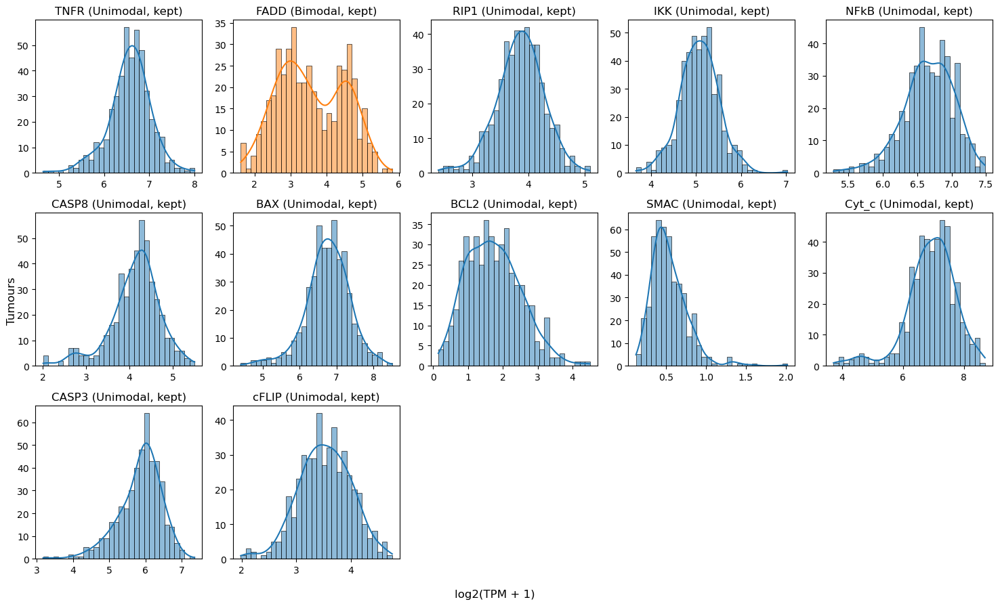

In [10]:
# Distribution of the nodes (log2(TPM + 1)), coloured by their normalization category
category_colors = {'Bimodal': 'tab:orange', 'ZeroInf': 'tab:green', 'Unimodal': 'tab:blue'}

n_cols = 5
n_rows = int(np.ceil(len(node_stats) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3 * n_rows), squeeze=False)
for ax, node in zip(axes.flat, node_stats.index):
    category = criteria_py.loc[node, 'Category']
    kept = 'kept' if node in rate_nodes else 'not used'
    sns.histplot(node_rna[node], bins=30, kde=True, color=category_colors.get(category, 'grey'), ax=ax)
    ax.set(title=f'{node} ({category}, {kept})', xlabel='', ylabel='')
for ax in axes.flat[len(node_stats):]:
    ax.set_visible(False)
fig.supxlabel('log2(TPM + 1)')
fig.supylabel('Tumours')
fig.tight_layout()
plt.show()

# 3. Mutations -> node ON / OFF
Each variant is classified (`profile.mutation_assignment`) and collapsed per gene and tumour (`profile.mutation_fusion`);
a gene with both activating and inactivating variants is set to activating. A node is `ON` / `OFF` if its mutated genes
agree, `Conflict` otherwise : conflicting nodes are not mutated.

In [11]:
criteria_mut = profile.mutation_assignment(TCGA_mut, database_dir=str(COMMON_DIR))
mutation_py, mutation_method = profile.mutation_fusion(criteria_mut)
mutation_py.columns = mutation_py.columns.astype(str)

# Mixed calls : activation dominates
mutation_py = mutation_py.mask(mutation_py.gt(0) & mutation_py.lt(1), 1.0)

# Node call per tumour
gene_node = pd.DataFrame([(gene, node) for node, genes in node_genes.items() for gene in genes], columns=['gene', 'node'])
mut_long = mutation_py.rename_axis(index='gene', columns='sample').stack().dropna().rename('BIN').reset_index()
mut_long = mut_long.merge(gene_node, on='gene')
mut_long['call'] = mut_long['BIN'].map({1.0: 'ON', 0.0: 'OFF'})
node_mut = mut_long.groupby(['node', 'sample'])['call'].agg(lambda calls: calls.iloc[0] if calls.nunique() == 1 else 'Conflict')
node_mut = node_mut.unstack().reindex(columns=samples)   # nodes x tumours
node_mut.apply(pd.Series.value_counts, axis=1).reindex(columns=['ON', 'OFF', 'Conflict']).fillna(0).astype(int)

- Assigning mutations...
-- Loading CancerMine and AlphaMissense databases...
-- Filtering AlphaMissense to 17 UniProt accessions (17 genes) ...
   ... scanned 216,175,351 rows, 159,562 matches so far
-- Loading CIViC database...
-- Assigning mutations...


/Users/saran/Git/pyPROFILE/pyPROFILE/mutation_processing.py:144: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  new_mutation = pd.pivot_table(mutation, values = 'BIN', index='gene_symbol', columns = 'model_name', dropna=False)
/Users/saran/Git/pyPROFILE/pyPROFILE/mutation_processing.py:145: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  new_mutation_method = pd.pivot_table(mutation_method, values = 'Method', index='gene_symbol', columns = 'model_name', aggfunc="first", dropna=False)


,ON,OFF,Conflict
node,,,
BAX,2,2,0
BCL2,1,0,0
CASP3,0,1,0
CASP8,0,12,0
IKK,1,4,0
NFkB,8,3,0
RIP1,1,2,0
TNFR,0,1,0
mXIAP,3,0,0


# 4. Personalize the model for each tumour
## Rate parameters of the core model
`profile.CellEnsemble` personalizes the rates of a node by multiplying the parameters `$u_<node>` (activation) and
`$d_<node>` (inactivation), that the CellFate model does not define. They are added (= 1, so the core model is
unchanged) as factors of the rates of the nodes personalized by expression.

In [13]:
model.network['BAX'].rt_up

'@logic ? 1.0 : 0.0'

In [ ]:
def add_rate_parameters(model, nodes):
    # Copy of the model with the rates of `nodes` multiplied by $u_<node> (rate_up) and $d_<node> (rate_down), both = 1
    model = model.copy()
    for node in nodes:
        model.network[node].rt_up = f'$u_{node} * ({model.network[node].rt_up})'
        model.network[node].rt_down = f'$d_{node} * ({model.network[node].rt_down})'
        model.param[f'$u_{node}'] = '1'
        model.param[f'$d_{node}'] = '1'
    return model

core_model = add_rate_parameters(model, rate_nodes)
pd.DataFrame({'rate_up': [core_model.network[n].rt_up for n in rate_nodes],
              'rate_down': [core_model.network[n].rt_down for n in rate_nodes]}, index=rate_nodes)

,rate_up,rate_down
FADD,$u_FADD * (0.0),$d_FADD * (0.0)
TNFR,$u_TNFR * (@logic ? 1.0 : 0.0),$d_TNFR * (@logic ? 0.0 : 1.0)
RIP1,$u_RIP1 * ((@logic ? 1.0 : 0.0)),$d_RIP1 * ((@logic ? 0.0 : 1.0))
IKK,$u_IKK * (@logic ? 1.0 : 0.0),$d_IKK * (@logic ? 0.0 : 1.0)
NFkB,$u_NFkB * (@logic ? 1.0 : 0.0),$d_NFkB * (@logic ? 0.0 : 1.0)
CASP8,$u_CASP8 * (@logic ? 1.0 : 0.0),$d_CASP8 * (@logic ? 0.0 : 1.0)
BAX,$u_BAX * (@logic ? 1.0 : 0.0),$d_BAX * (@logic ? 0.0 : 1.0)
BCL2,$u_BCL2 * ((@logic ? $TransRate : 0.0)),$d_BCL2 * (@logic ? 0.0 : 1.0)
SMAC,$u_SMAC * (@logic ? 1.0 : 0.0),$d_SMAC * (@logic ? 0.0 : 1.0)
Cyt_c,$u_Cyt_c * (@logic ? 1.0 : 0.0),$d_Cyt_c * (@logic ? 0.0 : 1.0)


In [15]:
core_model.param

OrderedDict([('time_tick', 0.1),
             ('max_time', 1.0),
             ('sample_count', 100000.0),
             ('discrete_time', 0.0),
             ('use_physrandgen', 0.0),
             ('seed_pseudorandom', 10.0),
             ('display_traj', 0.0),
             ('statdist_traj_count', 1.0),
             ('statdist_cluster_threshold', 0.8),
             ('thread_count', 8.0),
             ('statdist_similarity_cache_max_size', 20000),
             ('$ProdTNF_NFkB', '1'),
             ('$TransRate', '1/24'),
             ('$DivRate', '1/24'),
             ('$Degr_TNF', '1/6'),
             ('$TNF_induc', '0'),
             ('$u_FADD', '1'),
             ('$d_FADD', '1'),
             ('$u_TNFR', '1'),
             ('$d_TNFR', '1'),
             ('$u_RIP1', '1'),
             ('$d_RIP1', '1'),
             ('$u_IKK', '1'),
             ('$d_IKK', '1'),
             ('$u_NFkB', '1'),
             ('$d_NFkB', '1'),
             ('$u_CASP8', '1'),
             ('$d_CASP8', '1'),
 

## Personalized models
Mutations fix their nodes ON / OFF, expression scales the rates (`skip_initial_states=True`, so every model keeps the
initial state of the core model). One `.bnd`/`.cfg` pair per tumour in
`personalized_models/CellFate_TCGA_COAD_GDC/base/<tumour>/`, with `sample_count` MaBoSS trajectories per UPMaBoSS step
(the core `.cfg` uses 100,000).

In [19]:
sample_count = 10_000

ensemble = profile.CellEnsemble(df_mutations=node_mut,
                                df_transition_rates=df_transition.loc[samples],
                                df_init_states=df_norm.loc[samples],
                                dict_gene_nodes={node: node for node in node_mut.index},
                                dict_strict_gene_nodes={node: node for node in rate_nodes},
                                project_name=PROJECT_NAME,
                                df_groups=pd.Series(samples, index=samples).astype('category'),
                                skip_initial_states=True)
ensemble.personalize_cellmodel(core_model, num_processes=8, reload_model=False, simulation_sample=sample_count)
print('Models written in', ensemble.project_dir)

100%|██████████| 458/458 [00:00<00:00, 118777.67it/s]


Parameterizing the model


100%|██████████| 458/458 [00:06<00:00, 68.16it/s]

Models written in /Users/saran/Git/UppMaBoSS_PROFILE/personalized_models/CellFate_TCGA_COAD_GDC/


# 5. Model simulation with MaBoSS (no population update)
A first look at the personalized models, before UPMaBoSS : each model is simulated once with MaBoSS over the same
48 h (`max_time` = number of steps x step duration), without the `.upp` updates. Dying cells are not removed, dividing
cells are not duplicated, and `$TNF_induc` stays at its `.cfg` value (0 : no paracrine TNF, only the initial pulse).
`Death` and `Division` are never inactivated, so their probabilities are the fractions of cells that died / divided
at least once. The core model, not personalized, is simulated the same way as a reference.
Saved in `analysis/CellFate_model/results/maboss_personalized_TCGA_COAD_GDC_trajectory.csv`.

In [20]:
num_processes, threads_per_model = 4, 2
maboss_parameters = {'max_time': n_steps * step_duration, 'time_tick': step_duration, 'thread_count': threads_per_model}
maboss_trajectory_file = f'{RESULTS_DIR}/maboss_personalized_TCGA_COAD_GDC_trajectory.csv'

maboss_traj = profile.simulate_trajectory(ensemble.project_dir + 'base', all_nodes=True, parameters=maboss_parameters,
                                          num_processes=num_processes, output_file=maboss_trajectory_file)
maboss_nodes = list(maboss_traj.columns.drop(['model_id', 'timepoint']))

# Reference : the core model, not personalized, with the same parameters
core_ref = maboss.copy_and_update_parameters(model, {**maboss_parameters, 'sample_count': sample_count})
core_ref.network.set_output(list(core_ref.network.keys()))
core_traj = core_ref.run().get_nodes_probtraj().reindex(columns=maboss_nodes, fill_value=0)
maboss_traj

Simulating models:   0%|          | 0/458 [00:00<?, ?it/s]

,FASL,TNF,TNFR,DISC_TNF,DISC_FAS,FADD,RIP1,RIP1ub,RIP1K,IKK,NFkB,CASP8,BAX,BCL2,mROS,ROS,ATP,MPT,MOMP,SMAC,mcIAP,cIAP,Cyt_c,mXIAP,XIAP,apoptosome,CASP3,cFLIP,NonACD,Apoptosis,Survival,Division,Death,model_id,timepoint
TCGA-3L-AA1B-01A_0,0.0,0.923785,0.040244,0.005759,0.0,0.499916,0.024180,0.003673,0.006286,0.003333,0.001500,0.005112,0.004511,0.000004,0.511730,0.000350,0.683796,0.000040,0.000954,0.000812,0.129421,0.540650,0.000051,0.494514,0.179625,0.000000,0.000000,0.000144,0.130986,0.000000,0.000000,0.500214,0.520885,TCGA-3L-AA1B-01A,0.0
TCGA-3L-AA1B-01A_1,0.0,0.780373,0.099784,0.026471,0.0,0.499894,0.083680,0.022932,0.040491,0.022455,0.015282,0.026583,0.025567,0.000245,0.528834,0.006868,0.884236,0.002005,0.010941,0.010459,0.003039,0.549401,0.001044,0.487728,0.373306,0.000116,0.000000,0.002060,0.162994,0.000000,0.000084,0.500200,0.566898,TCGA-3L-AA1B-01A,1.0
TCGA-3L-AA1B-01A_2,0.0,0.656494,0.137261,0.048291,0.0,0.499883,0.128408,0.046545,0.086778,0.048469,0.040074,0.050453,0.049508,0.001274,0.536315,0.021638,0.954299,0.009938,0.033035,0.032276,0.000306,0.542846,0.006469,0.487148,0.437269,0.002094,0.000004,0.008508,0.103408,0.000000,0.000413,0.500172,0.586719,TCGA-3L-AA1B-01A,2.0
TCGA-3L-AA1B-01A_3,0.0,0.553001,0.154164,0.063579,0.0,0.499900,0.154274,0.065082,0.123473,0.073019,0.064637,0.071034,0.070671,0.004629,0.540598,0.035585,0.974736,0.021546,0.058081,0.057551,0.000627,0.531234,0.016127,0.490764,0.451866,0.006945,0.000246,0.018962,0.058127,0.000046,0.001383,0.500196,0.593311,TCGA-3L-AA1B-01A,3.0
TCGA-3L-AA1B-01A_4,0.0,0.467517,0.159398,0.071823,0.0,0.499891,0.168715,0.075869,0.148731,0.092282,0.086510,0.086822,0.087049,0.008435,0.543773,0.047607,0.972892,0.034815,0.083506,0.083795,0.001468,0.518808,0.030058,0.494179,0.449896,0.014105,0.000931,0.033380,0.038095,0.000299,0.003120,0.500209,0.595719,TCGA-3L-AA1B-01A,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TCGA-WS-AB45-01A_43,0.0,0.000605,0.637698,0.322521,0.0,0.499899,0.844395,0.653670,0.849271,0.701298,0.711397,0.092971,0.085956,0.722993,0.256768,0.240241,0.760908,0.239593,0.254593,0.251579,0.722949,0.727784,0.254568,0.714871,0.715355,0.015701,0.018710,0.724568,0.238512,0.019024,0.109548,0.690517,0.729105,TCGA-WS-AB45-01A,43.0
TCGA-WS-AB45-01A_44,0.0,0.000245,0.629615,0.319330,0.0,0.499903,0.838704,0.650662,0.843582,0.699936,0.710147,0.092202,0.085741,0.722836,0.258238,0.240679,0.760585,0.240070,0.254985,0.252198,0.722169,0.727804,0.254941,0.713532,0.714482,0.015716,0.018432,0.724139,0.239002,0.018899,0.107589,0.695051,0.729321,TCGA-WS-AB45-01A,44.0
TCGA-WS-AB45-01A_45,0.0,0.000100,0.622228,0.316434,0.0,0.499901,0.833551,0.647679,0.838306,0.698398,0.709432,0.091089,0.085199,0.722265,0.259634,0.241214,0.759853,0.240565,0.255214,0.252834,0.721652,0.727801,0.255139,0.712271,0.713225,0.015631,0.018426,0.723992,0.239579,0.018654,0.106482,0.698388,0.729642,TCGA-WS-AB45-01A,45.0
TCGA-WS-AB45-01A_46,0.0,0.000100,0.614070,0.313113,0.0,0.499899,0.827836,0.644564,0.833039,0.696418,0.708655,0.090132,0.084792,0.721780,0.260731,0.241942,0.759420,0.241362,0.255783,0.253087,0.721304,0.727798,0.255570,0.711388,0.712284,0.015605,0.018215,0.723938,0.239975,0.018410,0.104417,0.703013,0.729798,TCGA-WS-AB45-01A,46.0


Probability of the cell fates and of `Death` / `Division` over time : one thin line per tumour, the median of the
tumours (black) and the core model (red, dashed).

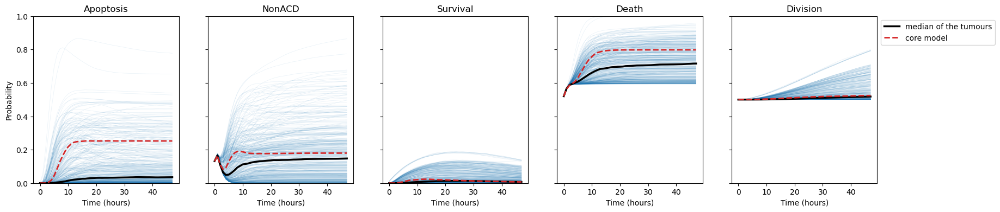

In [21]:
maboss_readouts = ['Apoptosis', 'NonACD', 'Survival', 'Death', 'Division']

fig, axes = plt.subplots(1, len(maboss_readouts), figsize=(4 * len(maboss_readouts), 4), sharey=True)
for ax, node in zip(axes, maboss_readouts):
    wide = maboss_traj.pivot(index='timepoint', columns='model_id', values=node)
    ax.plot(wide.index, wide.values, color='tab:blue', lw=0.5, alpha=0.1)
    ax.plot(wide.index, wide.median(axis=1), color='black', lw=2.5, label='median of the tumours')
    ax.plot(core_traj.index, core_traj[node], color='tab:red', lw=2, ls='--', label='core model')
    ax.set(title=node, xlabel='Time (hours)', ylim=(0, 1))
axes[0].set_ylabel('Probability')
axes[-1].legend(bbox_to_anchor=(1, 1), loc='upper left')
plt.show()

Node probabilities at the last time point : core model vs the distribution over the tumours, sorted by the spread
between tumours (nodes on top are the ones the personalization changes most).

In [22]:
maboss_endpoint = maboss_traj.groupby('model_id').tail(1).set_index('model_id')[maboss_nodes]
summary = maboss_endpoint.describe().T[['mean', 'std', 'min', 'max']]
summary.insert(0, 'core model', core_traj.iloc[-1])
summary.sort_values('std', ascending=False).round(3)

,core model,mean,std,min,max
mcIAP,0.000,0.159,0.240,0.000,1.000
mXIAP,0.000,0.151,0.238,0.000,1.000
BCL2,0.000,0.131,0.223,0.000,1.000
XIAP,0.000,0.138,0.221,0.000,1.000
MOMP,0.432,0.276,0.220,0.000,1.000
NFkB,0.000,0.130,0.220,0.000,1.000
SMAC,0.432,0.273,0.219,0.000,1.000
cFLIP,0.000,0.129,0.218,0.000,1.000
mROS,0.881,0.772,0.217,0.000,0.934
Cyt_c,0.432,0.257,0.214,0.000,1.000


# 6. Simulate the populations with UPMaBoSS and save
Each personalized model is simulated with UPMaBoSS (`maboss.UpdatePopulation` with the core `.upp`) : at each step,
the population ratio (`PopRatio`) and the probability of every node in the living cells. If a population dies out
before the last step, its population ratio is set to 0 and its node probabilities kept at their last value. Models
run in parallel threads, each driving MaBoSS : keep `num_processes * threads_per_model` <= number of CPU cores.
Saved in `analysis/CellFate_model/results/upmaboss_personalized_TCGA_COAD_GDC_trajectory.csv`.



**Notes**
Since I'm using Mac, I'm not sure whether this `ThreadPoolExecutor` function would work with Linux as well. I have some problem with that before. Check and if there is a problem, let me know.

In [ ]:
num_processes, threads_per_model = 4, 2
trajectory_file = f'{RESULTS_DIR}/upmaboss_personalized_TCGA_COAD_GDC_trajectory.csv'
steps = range(n_steps + 1)

def simulate_population(model_id, bnd_file, cfg_file):
    # UPMaBoSS simulation of one personalized model : population ratio and node probabilities at each step
    personalized = profile.load_maboss_model(bnd_file, cfg_file)
    personalized.update_parameters(thread_count=threads_per_model)
    nodes = list(personalized.network.keys())
    run = maboss.UpdatePopulation(personalized, upp_file).run()

    # One MaBoSS result per step run ; an extinct population has fewer results than population ratios
    df = pd.concat([result.get_last_nodes_probtraj(nodes) for result in run.results], ignore_index=True)
    df = df.reindex(columns=nodes).fillna(0).reindex(steps, method='ffill')
    pop_ratios = run.get_population_ratios().reset_index(drop=True).reindex(steps).fillna(0)
    df.insert(0, 'PopRatio', pop_ratios.values)
    df['model_id'] = model_id
    df['timepoint'] = df.index * step_duration
    df.index = [f'{model_id}_{t:g}' for t in df['timepoint']]
    return df

# Run the personalized models in parallel, with a progress bar
models = profile.find_models(ensemble.project_dir + 'base')
with ThreadPoolExecutor(max_workers=num_processes) as executor:
    trajectories = list(tqdm(executor.map(lambda item: simulate_population(item[0], *item[1]), models.items()),
                             total=len(models), desc='UPMaBoSS'))
prob_node = pd.concat(trajectories)
prob_node.to_csv(trajectory_file)

extinct = prob_node.groupby('model_id')['PopRatio'].last().eq(0)
print(extinct.sum(), 'populations died out')
prob_node[['PopRatio', 'Apoptosis', 'NonACD', 'Survival']].describe()

UPMaBoSS:   0%|          | 0/458 [00:00<?, ?it/s]

0 populations died out


,PopRatio,Apoptosis,NonACD,Survival
count,2.244200e+04,22442.000000,22442.000000,22442.000000
mean,4.793150e-01,0.011720,0.023473,0.114561
std,1.708881e-01,0.045504,0.038596,0.145263
min,5.517260e-11,0.000000,0.000000,0.000000
25%,3.570170e-01,0.000248,0.001315,0.000400
50%,5.125110e-01,0.001678,0.007373,0.017678
75%,5.972669e-01,0.008128,0.026994,0.251285
max,1.165265e+00,0.767556,0.238422,0.450633


# 7. Trajectory analysis
Trajectories reloaded from `results/` with `profile.load_trajectories`. The PCA and the clustering use the node
probabilities, which are all in [0, 1] ; the population ratio is analysed next to them. Nodes constant in every model
(e.g. `FASL`) carry no information and are dropped.

In [24]:
traj_df = profile.load_trajectories(trajectory_file)
pop_ratio = traj_df[['model_id', 'timepoint', 'PopRatio']]
variable_nodes = [n for n in traj_df.columns.drop(['model_id', 'timepoint', 'PopRatio']) if traj_df[n].std() > 1e-6]
traj = profile.TrajectoryComparison(traj_df[variable_nodes + ['model_id', 'timepoint']])
traj

TrajectoryComparison: 458 models x 49 timepoints x 31 nodes

## Population ratio
Population ratio over time, one line per tumour (thick : median).

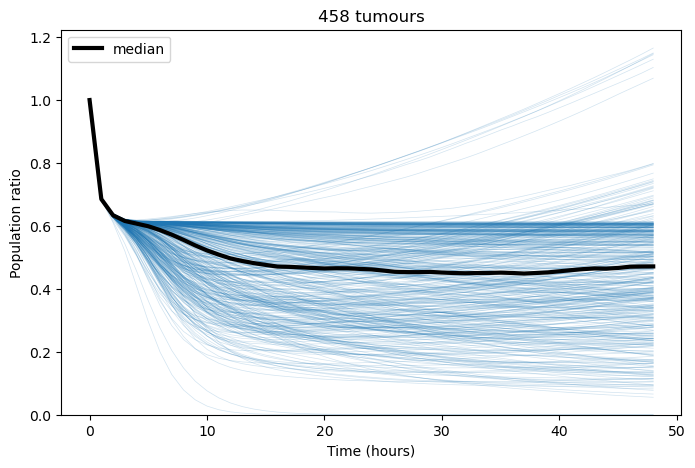

In [25]:
pop_wide = pop_ratio.pivot(index='timepoint', columns='model_id', values='PopRatio')
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pop_wide.index, pop_wide.values, color='tab:blue', lw=0.5, alpha=0.2)
ax.plot(pop_wide.index, pop_wide.median(axis=1), color='black', lw=3, label='median')
ax.set(xlabel='Time (hours)', ylabel='Population ratio', ylim=(0, None), title=f'{pop_wide.shape[1]} tumours')
ax.legend()
plt.show()

## 3D PCA of the trajectories
PCA of every state (tumour x time point). Left : states coloured by time ; right : one line per tumour.

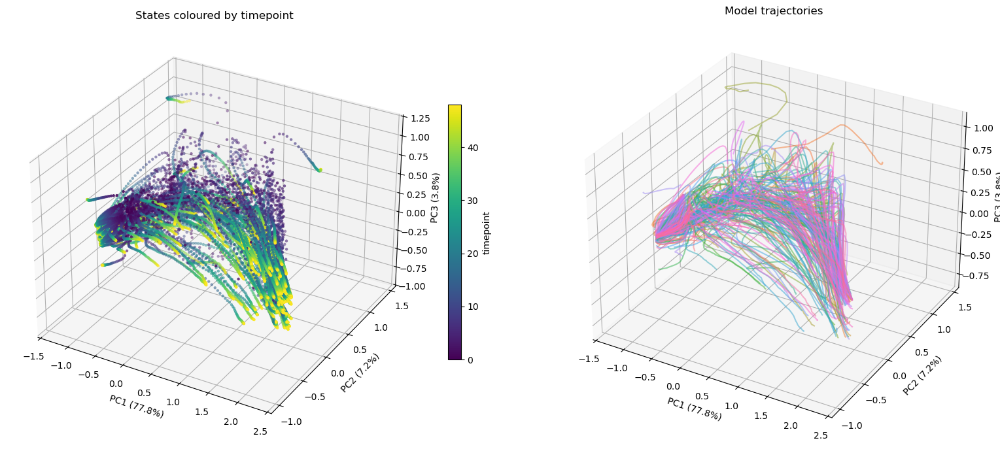

In [26]:
traj.pca_trajectory(n_components=10)
traj.plot_pca_overview(projection='3d', fig_size=(16, 7))

## Outcomes in 3D
Probability of the three cell fates of the model (`Apoptosis`, `NonACD` : non-apoptotic cell death, `Survival`) in the
living cells over time, one line per tumour, dot at the last time point.

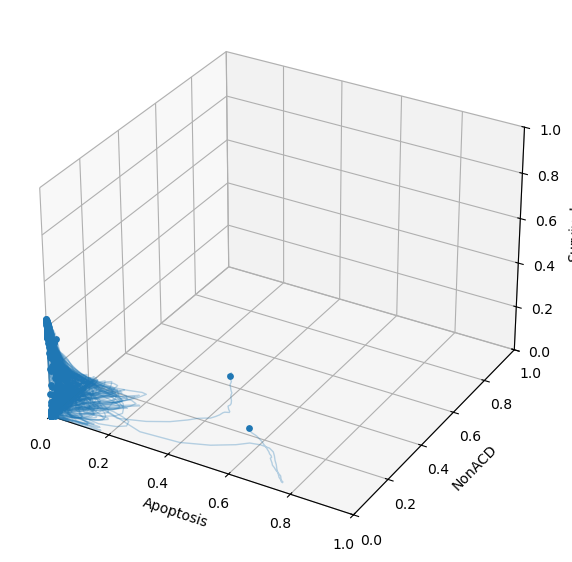

In [27]:
outcomes = ['Apoptosis', 'NonACD', 'Survival']

def plot_outcomes_3d(colors=None):
    ax = plt.figure(figsize=(8, 7)).add_subplot(projection='3d')
    for model, df in traj.simulation_df.groupby('model_id'):
        color = 'tab:blue' if colors is None else colors[model]
        ax.plot(*(df[o] for o in outcomes), color=color, lw=1, alpha=0.3)
        ax.scatter(*(df[o].iloc[-1:] for o in outcomes), color=color, s=15)
    ax.set(xlabel=outcomes[0], ylabel=outcomes[1], zlabel=outcomes[2], xlim=(0, 1), ylim=(0, 1), zlim=(0, 1))
    return ax

plot_outcomes_3d()
plt.show()

## Clustering the trajectories
DTW distance between whole trajectories (all variable nodes), then k-means on the distance matrix.

DTW distance:   0%|          | 0/457 [00:00<?, ?it/s]

k-means:   0%|          | 0/10 [00:00<?, ?it/s]

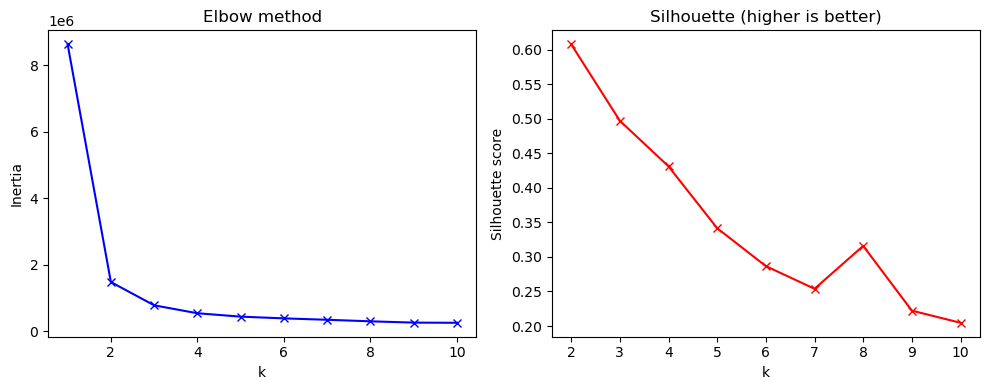

,inertia,silhouette
n_cluster,,
1,8.630862e+06,NaN
2,1.474771e+06,0.607728
3,7.748765e+05,0.496984
4,5.356501e+05,0.431009
5,4.336388e+05,0.341555
6,3.815783e+05,0.286690
7,3.394371e+05,0.253882
8,2.929617e+05,0.315960
9,2.540877e+05,0.222259


In [28]:
traj.calculate_distance_matrix(mode='trajectory')
traj.cluster_elbow_plot(n_cluster=11)

Choose k from the elbow / silhouette plot above.

In [29]:
n_cluster = 8
traj.calculate_clusters(n_cluster, method='kmeans')
palette = dict(zip(range(n_cluster), sns.color_palette('tab10', n_cluster)))
traj.clusters.value_counts().sort_index()

Calculated kmeans clustering with 8 clusters.


cluster
0     53
1    202
2     34
3     36
4     34
5     43
6      2
7     54
Name: count, dtype: int64

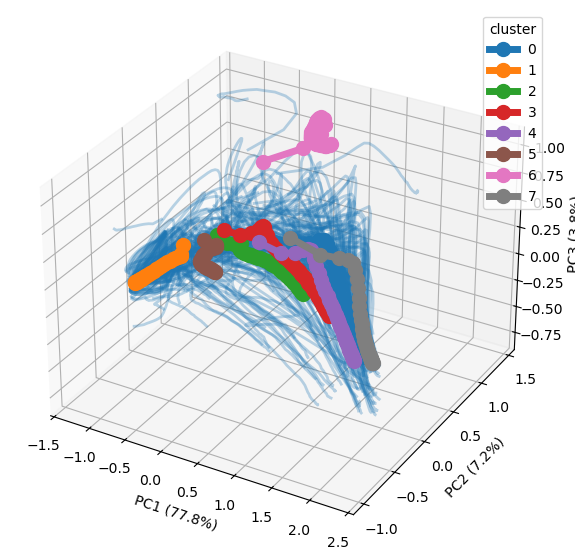

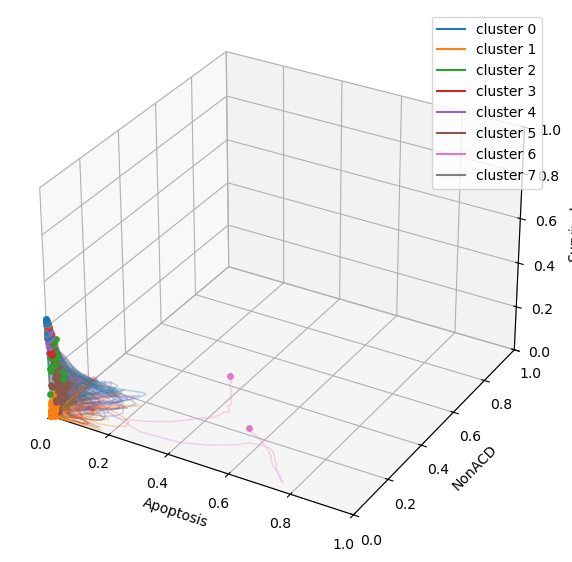

In [30]:
traj.plot_pca_trajectory(projection='3d', plot_cluster=True, fig_size=(9, 7))

ax = plot_outcomes_3d(traj.clusters.map(palette))
ax.legend(handles=[plt.Line2D([], [], color=c, label=f'cluster {k}') for k, c in palette.items()])
plt.show()

Rotating 3D PCA of the trajectories by cluster (thin : tumours, thick : cluster mean), saved as a GIF in
`analysis/CellFate_model/figures/personalization_TCGA_COAD_GDC/`.

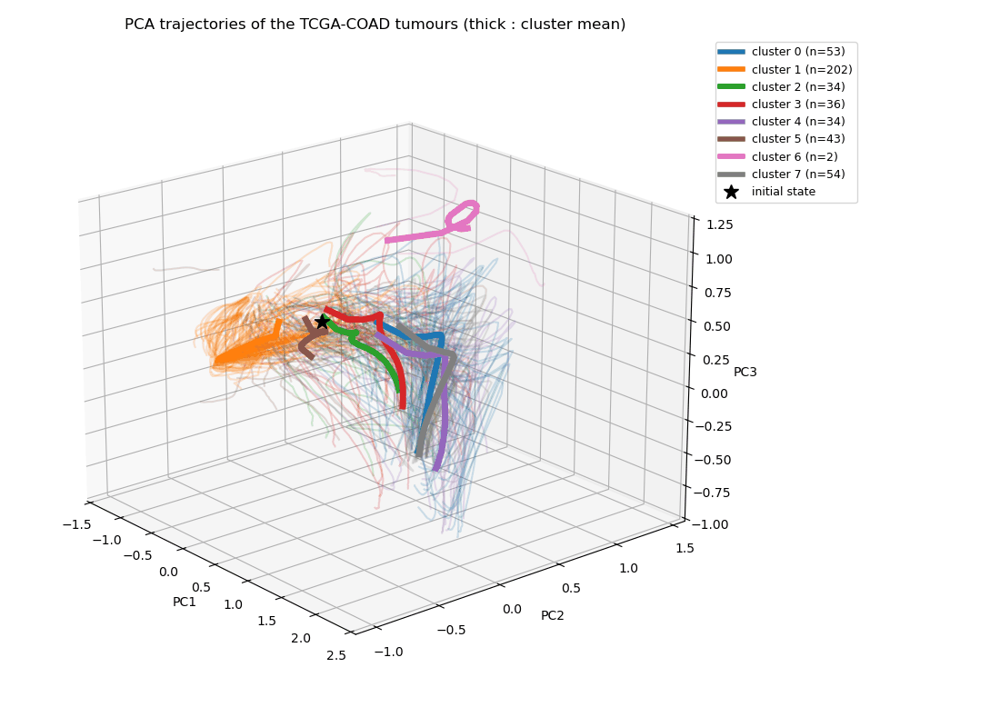

In [31]:
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.lines import Line2D
from IPython.display import Image

pcs = ['pc1', 'pc2', 'pc3']
pca_df = traj.pca_df.assign(cluster=traj.pca_df['model_id'].map(traj.cluster_dict))
cluster_mean = pca_df.groupby(['cluster', 'timepoint'])[pcs].mean()

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(projection='3d')
for model_id, df in pca_df.groupby('model_id'):
    ax.plot(*(df[c] for c in pcs), color=palette[df['cluster'].iloc[0]], lw=1.5, alpha=0.2)
for cluster, df in cluster_mean.groupby('cluster'):
    ax.plot(*(df[c] for c in pcs), color=palette[cluster], lw=5, marker='o', markersize=3)
ax.scatter(*pca_df.loc[pca_df['timepoint'] == 0, pcs].mean(), color='black', marker='*', s=150, depthshade=False)

handles = [Line2D([], [], color=c, lw=4, label=f'cluster {k} (n={(traj.clusters == k).sum()})') for k, c in palette.items()]
handles += [Line2D([], [], color='black', marker='*', ls='', markersize=12, label='initial state')]
ax.legend(handles=handles, loc='upper left', bbox_to_anchor=(1.0, 1), fontsize=9)
ax.set(xlabel='PC1', ylabel='PC2', zlabel='PC3', title='PCA trajectories of the TCGA-COAD tumours (thick : cluster mean)')
fig.subplots_adjust(left=0, right=0.75, bottom=0.03, top=0.95)

# Rotate about the PC3 axis at a fixed elevation of 20 degrees
def rotate(azim):
    ax.view_init(elev=20, azim=azim)
    return []

anim = FuncAnimation(fig, rotate, frames=np.arange(-40, 320, 2))
gif_path = f'{FIG_DIR}/pca_trajectory_3d_clusters_rotation.gif'
anim.save(gif_path, writer=PillowWriter(fps=20), dpi=100)
plt.close(fig)
Image(filename=gif_path)

Mean probability of the outcomes and mean population ratio over time, per cluster.

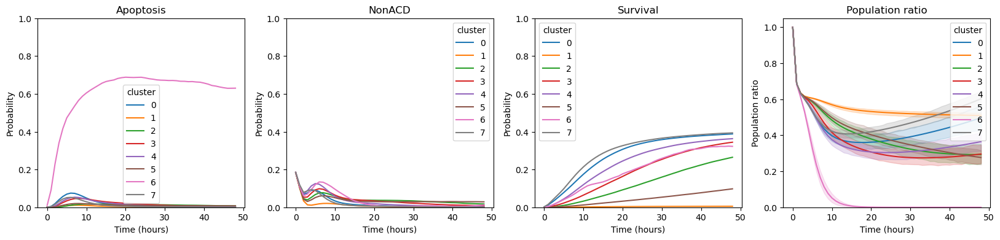

In [32]:
mean_traj = traj.cluster_mean_trajectory(outcomes).reset_index()
pop_cluster = pop_ratio.assign(cluster=pop_ratio['model_id'].map(traj.cluster_dict))

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, outcome in zip(axes, outcomes):
    sns.lineplot(data=mean_traj, x='timepoint', y=outcome, hue='cluster', palette=palette, ax=ax)
    ax.set(title=outcome, xlabel='Time (hours)', ylabel='Probability', ylim=(0, 1))
sns.lineplot(data=pop_cluster, x='timepoint', y='PopRatio', hue='cluster', palette=palette, ax=axes[-1])
axes[-1].set(title='Population ratio', xlabel='Time (hours)', ylabel='Population ratio', ylim=(0, None))
plt.show()

## Characterize the clusters
Per cluster mean of the endpoint node probabilities (how the model behaves) and of the personalization inputs (normalized
expression setting the rates, ON/OFF mutations : what drives it). Only the columns that differ between clusters are shown
(Kruskal-Wallis p < 0.05, sorted by p-value).

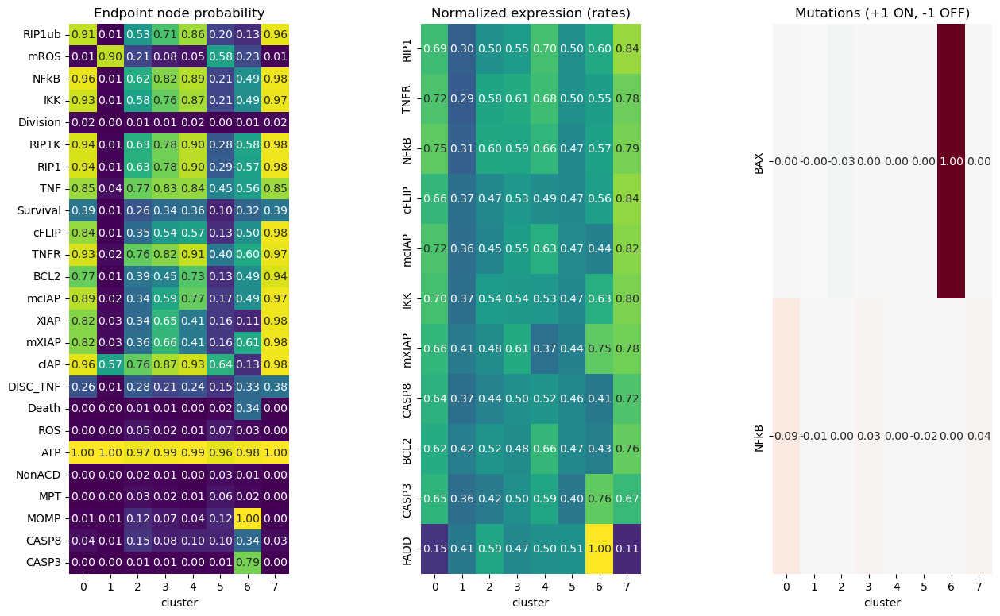

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
0,53.0,4.970051e-01,2.435396e-01,1.857968e-01,3.403824e-01,4.028835e-01,6.027658e-01,1.165265e+00
1,202.0,5.099371e-01,1.122033e-01,1.144373e-01,4.651210e-01,5.550704e-01,5.934590e-01,6.133276e-01
2,34.0,2.933048e-01,1.647290e-01,7.742008e-02,1.498936e-01,2.344434e-01,4.168013e-01,6.700681e-01
3,36.0,2.957080e-01,1.566885e-01,9.163360e-02,1.939505e-01,2.788757e-01,3.689363e-01,7.983151e-01
4,34.0,3.647779e-01,1.551612e-01,1.147111e-01,2.557462e-01,3.487886e-01,4.339810e-01,7.414684e-01
5,43.0,2.766954e-01,1.400321e-01,5.541414e-02,1.666139e-01,2.481239e-01,3.726556e-01,5.988710e-01
6,2.0,1.988752e-08,2.804717e-08,5.517260e-11,9.971344e-09,1.988752e-08,2.980369e-08,3.971986e-08
7,54.0,6.026227e-01,1.613788e-01,3.458108e-01,4.925115e-01,6.009482e-01,6.914707e-01,1.149590e+00


In [33]:
from scipy.stats import kruskal

def cluster_differences(table, alpha=0.05):
    # Mean of each column per cluster, for the columns that differ between clusters (Kruskal-Wallis p < alpha)
    table = traj.annotate_models(table)
    groups = [g.drop(columns='cluster') for _, g in table.groupby('cluster')]
    p_values = pd.Series({col: kruskal(*[g[col] for g in groups]).pvalue if table[col].nunique() > 1 else 1.0
                          for col in table.columns.drop('cluster')})
    means = table.groupby('cluster').mean().T
    return means.loc[p_values[p_values < alpha].sort_values().index]

endpoint = traj.simulation_df.groupby('model_id').tail(1).set_index('model_id')[traj.node_list]
endpoint['PopRatio'] = pop_ratio.groupby('model_id')['PopRatio'].last()
mutations = node_mut.T.apply(lambda calls: calls.map({'ON': 1, 'OFF': -1})).fillna(0)   # +1 ON, -1 OFF, 0 none

diffs = {'Endpoint node probability': (cluster_differences(endpoint[traj.node_list]).head(25), 'viridis', 0, 1),
         'Normalized expression (rates)': (cluster_differences(df_norm), 'viridis', 0, 1),
         'Mutations (+1 ON, -1 OFF)': (cluster_differences(mutations), 'RdBu_r', -1, 1)}
fig, axes = plt.subplots(1, 3, figsize=(15, 9), gridspec_kw={'wspace': 0.6})
for ax, (title, (means, cmap, vmin, vmax)) in zip(axes, diffs.items()):
    sns.heatmap(means, cmap=cmap, vmin=vmin, vmax=vmax, annot=True, fmt='.2f', cbar=False, ax=ax)
    ax.set(title=title, xlabel='cluster', ylabel='')
plt.show()

traj.annotate_models(endpoint[['PopRatio']]).groupby('cluster')['PopRatio'].describe()

## Simulated outcomes vs pathologic stage
The AJCC pathologic stage is used as the severity of the tumour (I : confined to the bowel wall, IV : distant
metastases ; tumours without a stage excluded). Probability of each outcome and population ratio at the last time point
per stage : Kruskal-Wallis test between the four stages, and Spearman correlation with the stage as an ordinal value
(does the readout go up or down with severity ?).

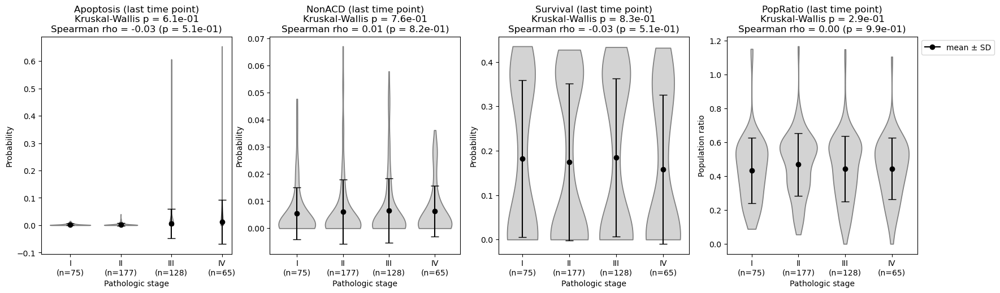

In [ ]:
from scipy.stats import kruskal, spearmanr, chi2_contingency

readouts = outcomes + ['PopRatio']
stage_order = ['I', 'II', 'III', 'IV']
stage_df = traj.annotate_models(endpoint[readouts]).join(TCGA_clin['STAGE'])
stage_df = stage_df[stage_df['STAGE'].isin(stage_order)]
stage_rank = stage_df['STAGE'].map({stage: i for i, stage in enumerate(stage_order)})
n_stage = stage_df['STAGE'].value_counts()

fig, axes = plt.subplots(1, len(readouts), figsize=(5 * len(readouts), 5))
for ax, readout in zip(axes, readouts):
    p_kw = kruskal(*[stage_df.loc[stage_df['STAGE'] == stage, readout] for stage in stage_order]).pvalue
    rho, p_rho = spearmanr(stage_rank, stage_df[readout])
    sns.violinplot(data=stage_df, x='STAGE', y=readout, order=stage_order, color='lightgrey', inner=None, cut=0, ax=ax)
    # Mean +/- SD per stage
    stage_stats = stage_df.groupby('STAGE')[readout].agg(['mean', 'std']).reindex(stage_order)
    
                fmt='o', color='black', markersize=6, capsize=5, lw=1.5, zorder=3)
    ax.set_xticks(range(len(stage_order)), [f'{stage}\n(n={n_stage[stage]})' for stage in stage_order])
    ax.set(xlabel='Pathologic stage', ylabel='Population ratio' if readout == 'PopRatio' else 'Probability',
           title=f'{readout} (last time point)\nKruskal-Wallis p = {p_kw:.1e}\nSpearman rho = {rho:.2f} (p = {p_rho:.1e})')
axes[-1].legend(handles=[plt.Line2D([], [], color='black', marker='o', label='mean ± SD')], bbox_to_anchor=(1, 1), loc='upper left')
plt.show()

Pathologic stage of the tumours in each trajectory cluster (chi-squared test).

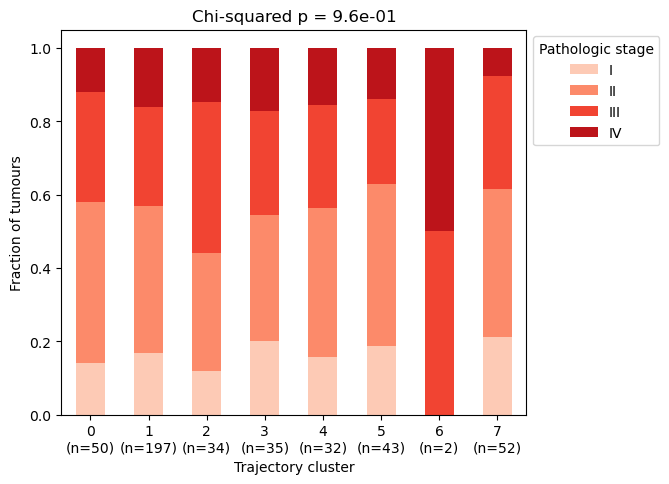

STAGE,I,II,III,IV
cluster,,,,
0,7,22,15,6
1,33,79,53,32
2,4,11,14,5
3,7,12,10,6
4,5,13,9,5
5,8,19,10,6
6,0,0,1,1
7,11,21,16,4


In [35]:
stage_counts = pd.crosstab(stage_df['cluster'], stage_df['STAGE']).reindex(columns=stage_order, fill_value=0)
p_value = chi2_contingency(stage_counts)[1]

fig, ax = plt.subplots(figsize=(6, 5))
stage_counts.div(stage_counts.sum(axis=1), axis=0).plot.bar(stacked=True, color=dict(zip(stage_order, sns.color_palette('Reds', len(stage_order)))), ax=ax)
ax.set_xticks(range(len(stage_counts)), [f'{k}\n(n={n})' for k, n in stage_counts.sum(axis=1).items()], rotation=0)
ax.set(xlabel='Trajectory cluster', ylabel='Fraction of tumours', title=f'Chi-squared p = {p_value:.1e}')
ax.legend(title='Pathologic stage', bbox_to_anchor=(1, 1), loc='upper left')
plt.show()
stage_counts

Rotating 3D plot of the three outcomes (Apoptosis, NonACD, Survival) over time by pathologic stage (thin : tumours with a
dot at the last time point, thick : stage mean ; tumours without a stage excluded), saved as a GIF in
`analysis/CellFate_model/figures/personalization_TCGA_COAD_GDC/`.

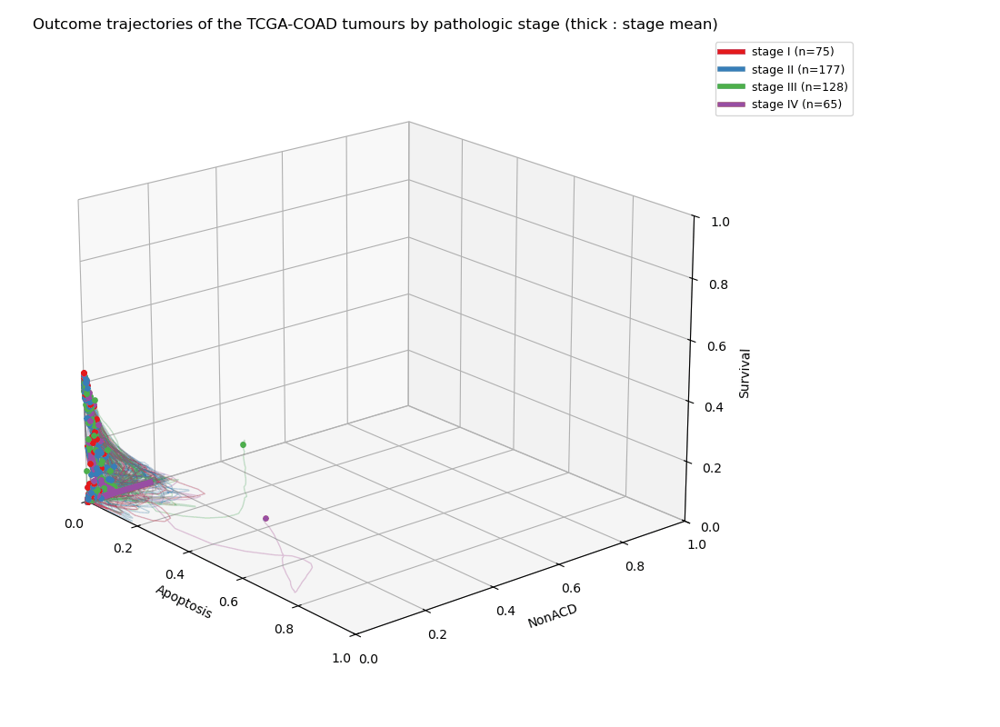

In [36]:
stage_palette = dict(zip(stage_order, sns.color_palette('Set1', len(stage_order))))
stage_sim = traj.simulation_df.assign(stage=traj.simulation_df['model_id'].map(TCGA_clin['STAGE']))
stage_sim = stage_sim[stage_sim['stage'].isin(stage_order)]
stage_mean = stage_sim.groupby(['stage', 'timepoint'])[outcomes].mean()

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(projection='3d')
for model_id, df in stage_sim.groupby('model_id'):
    color = stage_palette[df['stage'].iloc[0]]
    ax.plot(*(df[o] for o in outcomes), color=color, lw=1, alpha=0.3)
    ax.scatter(*(df[o].iloc[-1:] for o in outcomes), color=color, s=15)
for stage in stage_order:
    df = stage_mean.loc[stage]
    ax.plot(*(df[o] for o in outcomes), color=stage_palette[stage], lw=5)

handles = [Line2D([], [], color=c, lw=4, label=f'stage {k} (n={n_stage[k]})') for k, c in stage_palette.items()]
ax.legend(handles=handles, loc='upper left', bbox_to_anchor=(1.0, 1), fontsize=9)
ax.set(xlabel=outcomes[0], ylabel=outcomes[1], zlabel=outcomes[2], xlim=(0, 1), ylim=(0, 1), zlim=(0, 1),
       title='Outcome trajectories of the TCGA-COAD tumours by pathologic stage (thick : stage mean)')
fig.subplots_adjust(left=0, right=0.75, bottom=0.03, top=0.95)

# Rotate about the vertical axis at a fixed elevation of 20 degrees
def rotate(azim):
    ax.view_init(elev=20, azim=azim)
    return []

anim = FuncAnimation(fig, rotate, frames=np.arange(-40, 320, 2))
gif_path = f'{FIG_DIR}/outcomes_3d_stage_rotation.gif'
anim.save(gif_path, writer=PillowWriter(fps=20), dpi=100)
plt.close(fig)
Image(filename=gif_path)

Readouts at the last time point. First : correlation between the two death modes, Apoptosis and NonACD (every tumour,
linear fit). Second : density contours of the population ratio vs Apoptosis, one panel per pathologic stage (KDE,
5 levels ; grey : tumours of every stage, for reference ; tumours without a stage excluded).

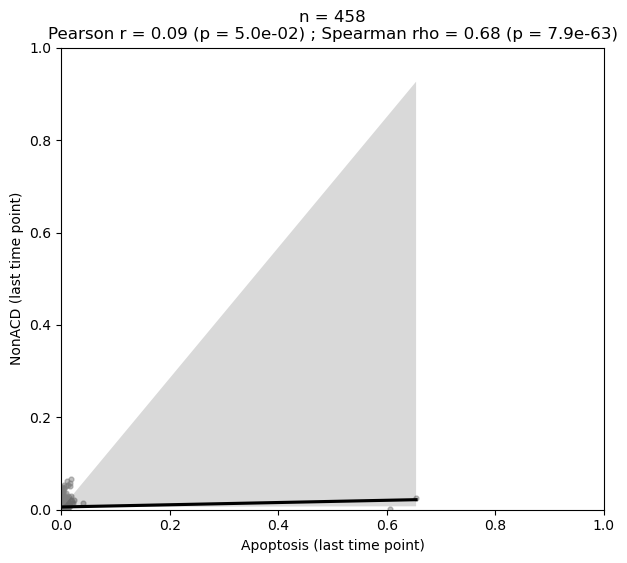

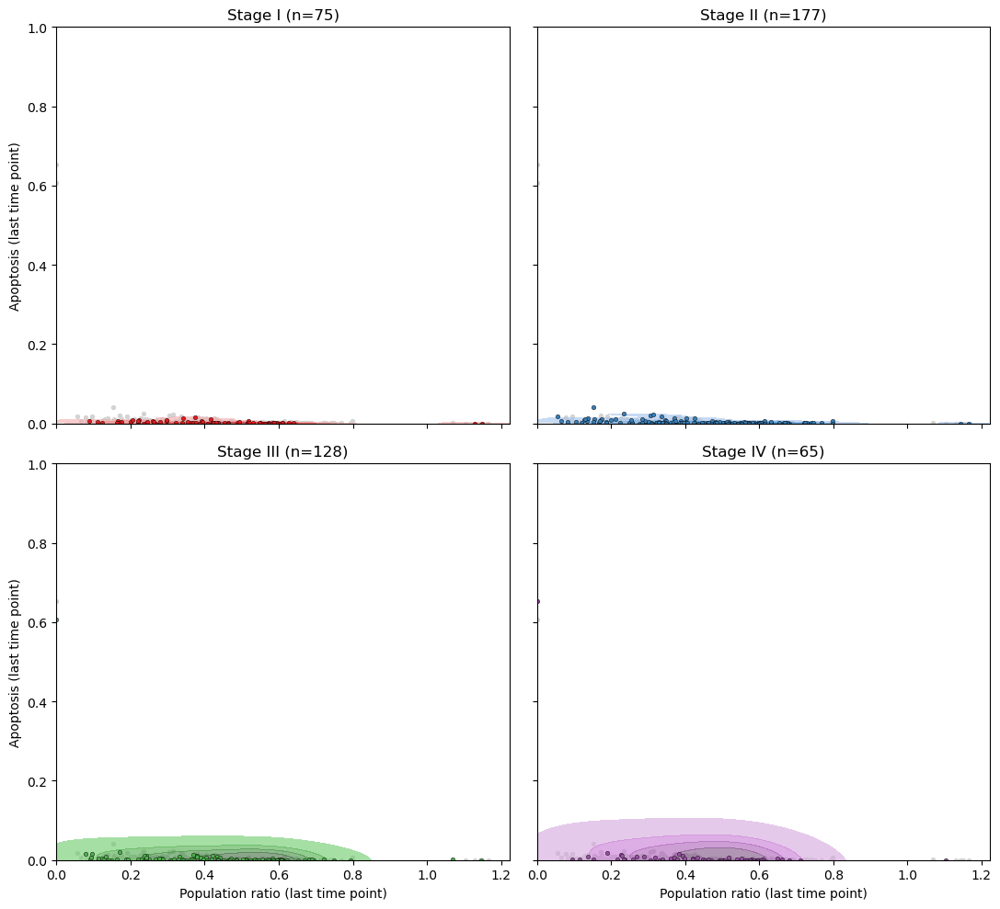

In [ ]:
from scipy.stats import pearsonr

# 2. Population ratio vs Apoptosis density, one panel per stage (grey : tumours of every stage)
pop_max = stage_df['PopRatio'].max() * 1.05
fig, axes = plt.subplots(2, 2, figsize=(11, 10), sharex=True, sharey=True)
for ax, stage in zip(axes.flat, stage_order):
    sub = stage_df[stage_df['STAGE'] == stage]
    ax.scatter(stage_df['PopRatio'], stage_df['Apoptosis'], color='lightgrey', s=8)
    sns.kdeplot(data=sub, x='PopRatio', y='Apoptosis', color=stage_palette[stage], fill=True, alpha=0.6,
                levels=5, thresh=0.05, clip=((0, pop_max), (0, 1)), ax=ax)
    ax.scatter(sub['PopRatio'], sub['Apoptosis'], color=stage_palette[stage], s=10, edgecolor='k', lw=0.3)
    ax.set(xlim=(0, pop_max), ylim=(0, 1), title=f'Stage {stage} (n={n_stage[stage]})',
           xlabel='Population ratio (last time point)', ylabel='Apoptosis (last time point)')
fig.tight_layout()
plt.show()